In [2]:

import os
import zipfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)


TensorFlow version: 2.21.0
GPU available: False


In [1]:
!pip -q install -U kagglehub gradio

In [4]:
import os
from google.colab import userdata

kaggle_token = userdata.get("KAGGLE_API_TOKEN")
if not kaggle_token:
    raise ValueError("Add KAGGLE_API_TOKEN in Colab Secrets and enable notebook access.")

# KaggleHub reads this environment variable for token-based authentication.
os.environ["KAGGLE_API_TOKEN"] = kaggle_token

import kagglehub

dataset_path = kagglehub.dataset_download("alessiocorrado99/animals10")
print("Dataset downloaded to:", dataset_path)

Using Colab cache for faster access to the 'animals10' dataset.
Dataset downloaded to: /kaggle/input/animals10


In [5]:
from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 123

root = Path(dataset_path)
candidates = [p for p in root.rglob("raw-img") if p.is_dir()]
if candidates:
    data_dir = candidates[0]
else:
    # Fallback: find a directory containing multiple class subfolders.
    dirs = [p for p in root.rglob("*") if p.is_dir()]
    dirs.sort(key=lambda p: len([d for d in p.iterdir() if d.is_dir()]), reverse=True)
    data_dir = next((p for p in dirs if len([d for d in p.iterdir() if d.is_dir()]) >= 5), None)
    if data_dir is None:
        raise FileNotFoundError(f"Could not find class folders under {root}. Inspect the downloaded files.")

print("Image directory:", data_dir)
print("Class folders:", sorted(p.name for p in data_dir.iterdir() if p.is_dir()))

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, label_mode="int"
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, label_mode="int"
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Number of classes:", num_classes)
print("Class names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

Image directory: /kaggle/input/animals10/raw-img
Class folders: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
Found 26179 files belonging to 10 classes.
Using 20944 files for training.
Found 26179 files belonging to 10 classes.
Using 5235 files for validation.
Number of classes: 10
Class names: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']


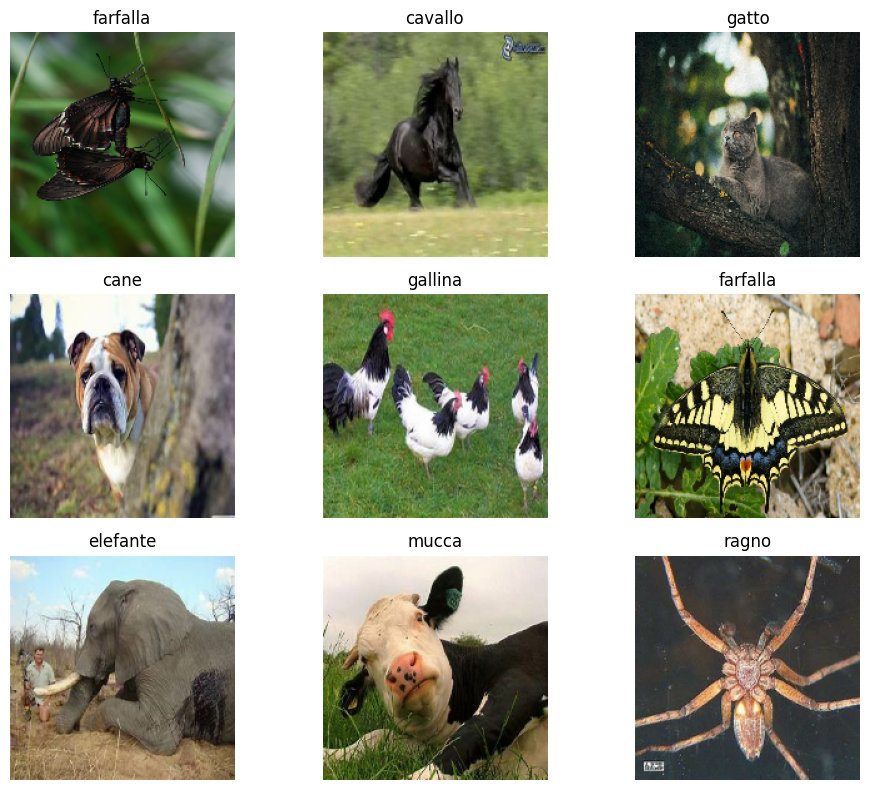

In [6]:
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    n = min(9, len(images))
    for i in range(n):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [7]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

base_model = MobileNetV2(
    input_shape=IMAGE_SIZE + (3,), include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=IMAGE_SIZE + (3,))
x = layers.Lambda(preprocess_input)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

/tmp/ipykernel_1204/1549141317.py:5: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
EPOCHS = 5  # Increase to 8-10 if you have enough GPU time.
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

Epoch 1/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 716s 1s/step - accuracy: 0.9053 - loss: 0.3058 - val_accuracy: 0.9496 - val_loss: 0.1655
Epoch 2/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 702s 1s/step - accuracy: 0.9508 - loss: 0.1656 - val_accuracy: 0.9542 - val_loss: 0.1517
Epoch 3/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 745s 1s/step - accuracy: 0.9575 - loss: 0.1413 - val_accuracy: 0.9509 - val_loss: 0.1648
Epoch 4/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 820s 1s/step - accuracy: 0.9605 - loss: 0.1295 - val_accuracy: 0.9551 - val_loss: 0.1597
Epoch 5/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 800s 1s/step - accuracy: 0.9638 - loss: 0.1182 - val_accuracy: 0.9559 - val_loss: 0.1632


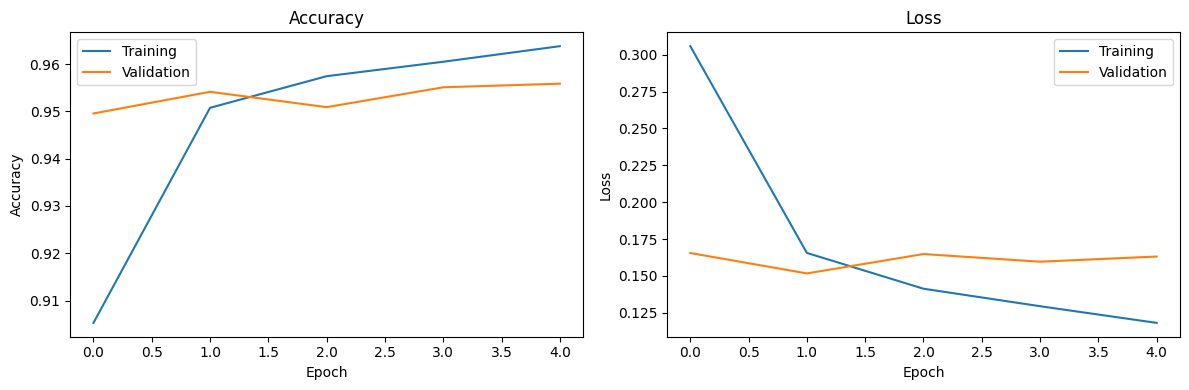

Validation accuracy: 95.59%


In [9]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
print(f"Validation accuracy: {val_accuracy:.2%}")

In [10]:
import json
MODEL_PATH = "/content/multiclass_animal_classifier.keras"
LABELS_PATH = "/content/animal_class_names.json"

model.save(MODEL_PATH)
with open(LABELS_PATH, "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

print("Saved model:", MODEL_PATH)
print("Saved labels:", LABELS_PATH)

Saved model: /content/multiclass_animal_classifier.keras
Saved labels: /content/animal_class_names.json


In [11]:
!pip -q install gradio

In [12]:
import gradio as gr
from PIL import Image

# Optional friendly names for Animals-10's Italian folder names.
english_names = {
    "cane": "Dog", "cavallo": "Horse", "elefante": "Elephant",
    "farfalla": "Butterfly", "gallina": "Chicken", "gatto": "Cat",
    "mucca": "Cow", "pecora": "Sheep", "ragno": "Spider",
    "scoiattolo": "Squirrel"
}

def predict_animal(image):
    if image is None:
        return {"Please upload an image": 1.0}
    image = image.convert("RGB").resize(IMAGE_SIZE)
    arr = np.array(image, dtype=np.float32)
    probabilities = model.predict(np.expand_dims(arr, axis=0), verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:3]
    result = {}
    for idx in top_indices:
        raw_name = class_names[int(idx)]
        display_name = english_names.get(raw_name.lower(), raw_name.replace("_", " ").title())
        result[display_name] = float(probabilities[idx])
    return result

demo = gr.Interface(
    fn=predict_animal,
    inputs=gr.Image(type="pil", label="Upload an animal image"),
    outputs=gr.Label(num_top_classes=3, label="Predictions"),
    title="Multi-Class Animal Image Classifier",
    description=f"Classifies images into {num_classes} animal categories. Model predictions can be wrong; use as a demo.",
    examples=None
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b8d4978f8300fa167f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [13]:
from google.colab import files
files.download(MODEL_PATH)
files.download(LABELS_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>